# configuration & loadings

In [1]:
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gvns").exists():
    PROJECT_ROOT = (
        Path(__file__).parent.parent.parent.parent
        if "__file__" in locals()
        else Path.cwd().parent.parent.parent
    )

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\HP\Documents\GitHub\GVNS-implementation


In [2]:
# load data and models
DATA_PATH = PROJECT_ROOT / "gvns" / "ls_data" / "learning_dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (39889, 30)


,instance_name,gvns_iter,neigh_id,n_customers,n_vehicles,horizon,sync_ratio,avg_tw_width,min_tw_width,tw_tightness,...,pen_ratio,penT_ratio,penS_ratio,k,k_norm,delta,elapsed,strategy,rel_delta,success
0,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,9.999888e-07,0.000000,9.999888e-07,0,0.0,9.999293e+05,0.021839,0,0.027776,1
1,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,2.143647e-05,0.000020,9.999771e-07,0,0.0,1.999635e+06,0.148822,0,0.057132,1
2,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,9.999873e-07,0.000000,9.999873e-07,0,0.0,3.372098e+02,0.001002,0,0.000010,1
3,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,9.999862e-07,0.000000,9.999862e-07,0,0.0,9.999777e+05,0.509428,0,0.030302,1
4,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,4.018982e-05,0.000039,9.999612e-07,0,0.0,1.999276e+06,0.771377,0,0.062477,1


In [4]:
REG_MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_delta_regressor.pkl"
CLS_MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_success_classifier.pkl"

REG_FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_regressor_features.json"
CLS_FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_classifier_features.json"

reg_model = joblib.load(REG_MODEL_PATH)
cls_model = joblib.load(CLS_MODEL_PATH)

with open(REG_FEATURES_PATH) as f:
    reg_features = json.load(f)

with open(CLS_FEATURES_PATH) as f:
    cls_features = json.load(f)

In [5]:
required_cols = {
    "instance_name",
    "gvns_iter",
    "neigh_id",
    "strategy",
    "rel_delta",
    "success",
}

missing = required_cols - set(df.columns)
assert not missing, f"Missing columns: {missing}"

assert set(reg_features).issubset(df.columns)
assert set(cls_features).issubset(df.columns)

# Predictions (2 heads)

In [6]:
X_reg = df[reg_features]
X_cls = df[cls_features]

df["pred_rel_delta"] = reg_model.predict(X_reg)
df["p_success"] = cls_model.predict_proba(X_cls)[:, 1]

# expected utility
df["score"] = df["p_success"] * df["pred_rel_delta"]

df[["strategy", "pred_rel_delta", "p_success", "score"]].head()

,strategy,pred_rel_delta,p_success,score
0,0,0.036301,0.973873,0.035352
1,0,0.048288,0.984910,0.047560
2,0,0.036654,0.972242,0.035636
3,0,0.052563,0.974195,0.051206
4,0,0.057216,0.986354,0.056435


In [7]:
# pair FI / BI strategies
KEYS = ["instance_name", "gvns_iter", "neigh_id"]

df_fi = df[df["strategy"] == 0].set_index(KEYS)
df_bi = df[df["strategy"] == 1].set_index(KEYS)

paired = df_fi.join(
    df_bi,
    lsuffix="_fi",
    rsuffix="_bi",
    how="inner"
)

print(f"Paired states: {len(paired)}")
paired.head()

Paired states: 3344538


n_customers_fi  n_vehicles_fi  horizon_fi  \
instance_name gvns_iter neigh_id                                              
C102_30_15    1         0                     30             10      1236.0   
                        0                     30             10      1236.0   
                        0                     30             10      1236.0   
                        0                     30             10      1236.0   
                        0                     30             10      1236.0   

                                  sync_ratio_fi  avg_tw_width_fi  \
instance_name gvns_iter neigh_id                                   
C102_30_15    1         0                   0.5       372.774194   
                        0                   0.5       372.774194   
                        0                   0.5       372.774194   
                        0                   0.5       372.774194   
                        0                   0.5       372.774194   

                                  min_tw_width_fi  tw_tightness_fi  \
instance_name gvns_iter neigh_id                                     
C102_30_15    1         0                    45.0         0.301597   
                        0                    45.0         0.301597   
                        0                    45.0         0.301597   
                        0                    45.0         0.301597   
                        0                    45.0         0.301597   

                                  early_tw_ratio_fi  late_tw_ratio_fi  \
instance_name gvns_iter neigh_id                                        
C102_30_15    1         0                       0.5               0.3   
                        0                       0.5               0.3   
                        0                       0.5               0.3   
                        0                       0.5               0.3   
                        0                       0.5               0.3   

                                  stagnation_ls_fi  ...  k_bi  k_norm_bi  \
instance_name gvns_iter neigh_id                    ...                    
C102_30_15    1         0                        0  ...     0        0.0   
                        0                        0  ...     0        0.0   
                        0                        0  ...     0        0.0   
                        0                        0  ...     0        0.0   
                        0                        0  ...     0        0.0   

                                      delta_bi  elapsed_bi  strategy_bi  \
instance_name gvns_iter neigh_id                                          
C102_30_15    1         0         8.999829e+06    0.731005            1   
                        0         1.999960e+06    0.731001            1   
                        0         1.999951e+06    0.760996            1   
                        0         6.997736e+06    0.622001            1   
                        0         7.998385e+06    0.689997            1   

                                  rel_delta_bi  success_bi  pred_rel_delta_bi  \
instance_name gvns_iter neigh_id                                                
C102_30_15    1         0             0.249993           1           0.207064   
                        0             0.074071           1           0.206134   
                        0             0.079996           1           0.182735   
                        0             0.304242           1           0.209500   
                        0             0.499810           1           0.214855   

                                  p_success_bi  score_bi  
instance_name gvns_iter neigh_id                          
C102_30_15    1         0             0.974508  0.201786  
                        0             0.970287  0.200009  
                        0             0.970291  0.177306  
                        0             0.989332  0.207265  
                   

In [8]:
# decision rule 
paired["ml_choice"] = (
    paired["score_bi"] > paired["score_fi"]
).astype(int)

paired["realized_ml"] = np.where(
    paired["ml_choice"] == 1,
    paired["rel_delta_bi"],
    paired["rel_delta_fi"]
)

# baselines
paired["realized_fi"] = paired["rel_delta_fi"]
paired["realized_bi"] = paired["rel_delta_bi"]

paired[["ml_choice", "realized_ml"]].head()

ml_choice  realized_ml
instance_name gvns_iter neigh_id                        
C102_30_15    1         0                 1     0.249993
                        0                 1     0.074071
                        0                 1     0.079996
                        0                 1     0.304242
                        0                 1     0.499810

# performance comparison 

In [9]:
summary = {
    "FI": paired["realized_fi"].mean(),
    "BI": paired["realized_bi"].mean(),
    "ML (2-head)": paired["realized_ml"].mean(),
}

pd.Series(summary)

FI             0.003177
BI             0.008014
ML (2-head)    0.009733
dtype: float64

In [11]:
inst_perf = paired.groupby("instance_name").agg(
    FI=("realized_fi", "mean"),
    BI=("realized_bi", "mean"),
    ML=("realized_ml", "mean"),
)

inst_perf.head()

,FI,BI,ML
instance_name,,,
C102_30_15,0.020270,0.070270,0.079984
C102_30_3,0.024150,0.035339,0.049874
C102_30_9,0.017248,0.027159,0.038390
C106_100_10,0.003344,0.007413,0.009079
C106_100_20,0.003047,0.007886,0.009448


In [12]:
wins = {
    "ML > FI": (inst_perf["ML"] > inst_perf["FI"]).mean(),
    "ML > BI": (inst_perf["ML"] > inst_perf["BI"]).mean(),
}

pd.Series(wins)

ML > FI    1.0
ML > BI    1.0
dtype: float64

C:\Users\HP\AppData\Local\Temp\ipykernel_19220\932613498.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


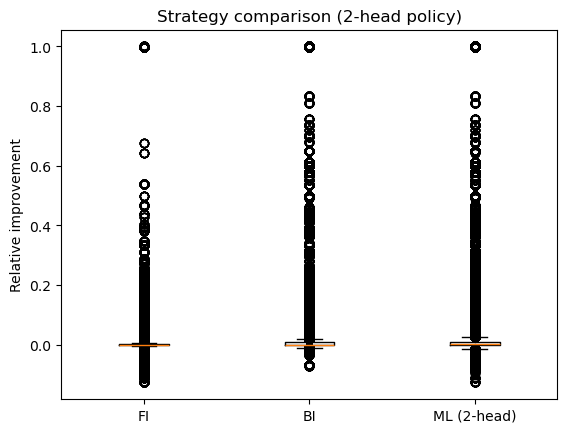

In [13]:
# distribution plots 
plt.boxplot(
    [
        paired["realized_fi"],
        paired["realized_bi"],
        paired["realized_ml"],
    ],
    labels=["FI", "BI", "ML (2-head)"],
)
plt.ylabel("Relative improvement")
plt.title("Strategy comparison (2-head policy)")
plt.show()

In [15]:
# decision behavior 
paired["ml_choice"].value_counts(normalize=True)

ml_choice
1    0.662866
0    0.337134
Name: proportion, dtype: float64